In [1]:
%pip install -q ultralytics==8.4.174

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 7.1 MB/s eta 0:00:00


In [6]:
from pathlib import Path
from google.colab import files
from ultralytics import YOLO
import torch

uploaded = files.upload()

for prefixo, destino in [
    ("best_deteccao", "/content/best_deteccao.pt"),
    ("best_classificao", "/content/best_classificao.pt")
]:
    candidatos = [
        nome for nome in uploaded
        if Path(nome).stem.startswith(prefixo)
        and Path(nome).suffix.lower() == ".pt"
    ]

    assert len(candidatos) == 1, (
        f"Selecione exatamente um arquivo para {prefixo}."
    )

    Path(destino).write_bytes(uploaded[candidatos[0]])

del uploaded

DETECTOR_PATH = Path("/content/best_deteccao.pt")
CLASSIFIER_PATH = Path("/content/best_classificao.pt")

detector = YOLO(str(DETECTOR_PATH))
classificador = YOLO(str(CLASSIFIER_PATH))

assert detector.task == "detect"
assert classificador.task == "classify"
assert list(detector.names.values()) == ["folha"]

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Os dois modelos foram carregados!")
print("Classes do classificador:", classificador.names)

Saving best_deteccao.pt to best_deteccao (2).pt
Saving best_classificao.pt to best_classificao (2).pt
Os dois modelos foram carregados!
Classes do classificador: {0: 'anthracnose', 1: 'black_shank', 2: 'brown_spot', 3: 'cmv', 4: 'frog_eye', 5: 'genetic_abnormality', 6: 'healthy', 7: 'nematodes', 8: 'potato_tuber_moth', 9: 'pvy', 10: 'sunscald', 11: 'target_spot', 12: 'tmv', 13: 'tswv', 14: 'weather_fleck', 15: 'wildfire'}


In [7]:
from PIL import Image

uploaded = files.upload()

PHOTO_DIR = Path("/content/fotos_integracao")
PHOTO_DIR.mkdir(parents=True, exist_ok=True)

PHOTO_PATHS = []

for nome, conteudo in uploaded.items():
    if Path(nome).suffix.lower() in [".jpg", ".jpeg", ".png"]:
        destino = PHOTO_DIR / Path(nome).name
        destino.write_bytes(conteudo)

        with Image.open(destino) as imagem:
            imagem.verify()

        PHOTO_PATHS.append(destino)

del uploaded

assert len(PHOTO_PATHS) == 3, (
    f"Recebi {len(PHOTO_PATHS)} imagens. Selecione as três fotos."
)

print("As três fotos foram carregadas!")
for caminho in PHOTO_PATHS:
    print("-", caminho.name)

Saving WhatsApp Image 2026-10-11 at 23.32.07.jpeg to WhatsApp Image 2026-10-11 at 23.32.07.jpeg
Saving WhatsApp Image 2026-10-11 at 23.32.08.jpeg to WhatsApp Image 2026-10-11 at 23.32.08.jpeg
Saving WhatsApp Image 2026-10-11 at 23.32.08 (1).jpeg to WhatsApp Image 2026-10-11 at 23.32.08 (1).jpeg
As três fotos foram carregadas!
- WhatsApp Image 2026-10-11 at 23.32.07.jpeg
- WhatsApp Image 2026-10-11 at 23.32.08.jpeg
- WhatsApp Image 2026-10-11 at 23.32.08 (1).jpeg



Foto 1 — folha 1
Confiança da detecção: 76.4%
Classe prevista: healthy
Confiança da classificação: 40.7%
Três classes mais prováveis:
  healthy: 40.7%
  wildfire: 37.0%
  pvy: 11.6%


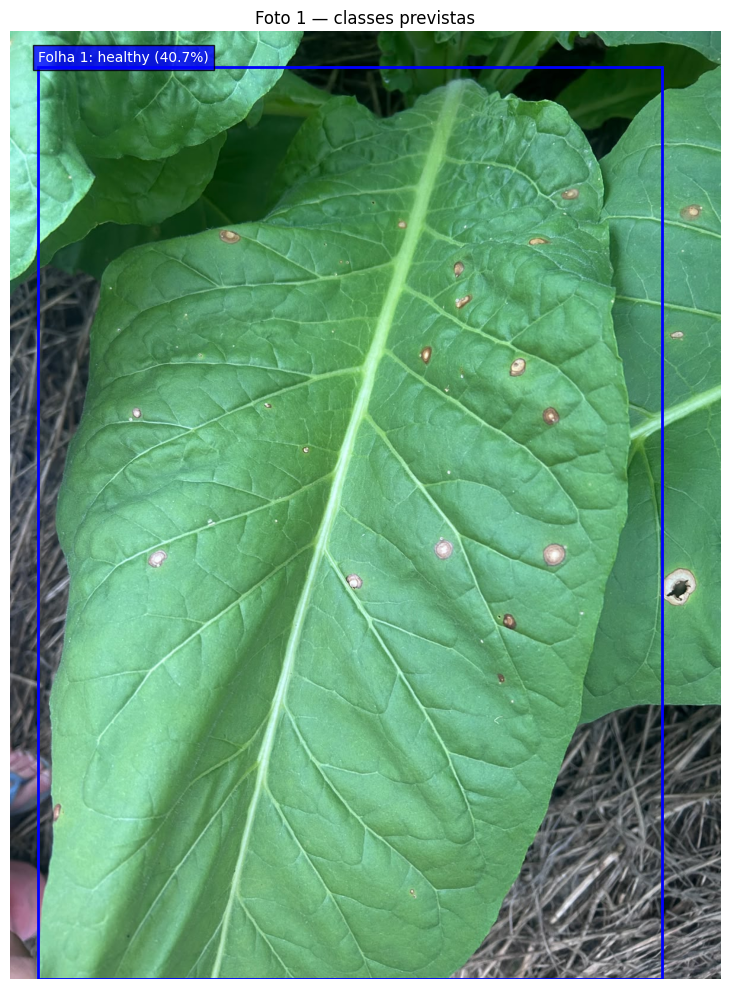


Foto 2 — folha 1
Confiança da detecção: 61.1%
Classe prevista: wildfire
Confiança da classificação: 86.6%
Três classes mais prováveis:
  wildfire: 86.6%
  sunscald: 6.6%
  cmv: 4.8%


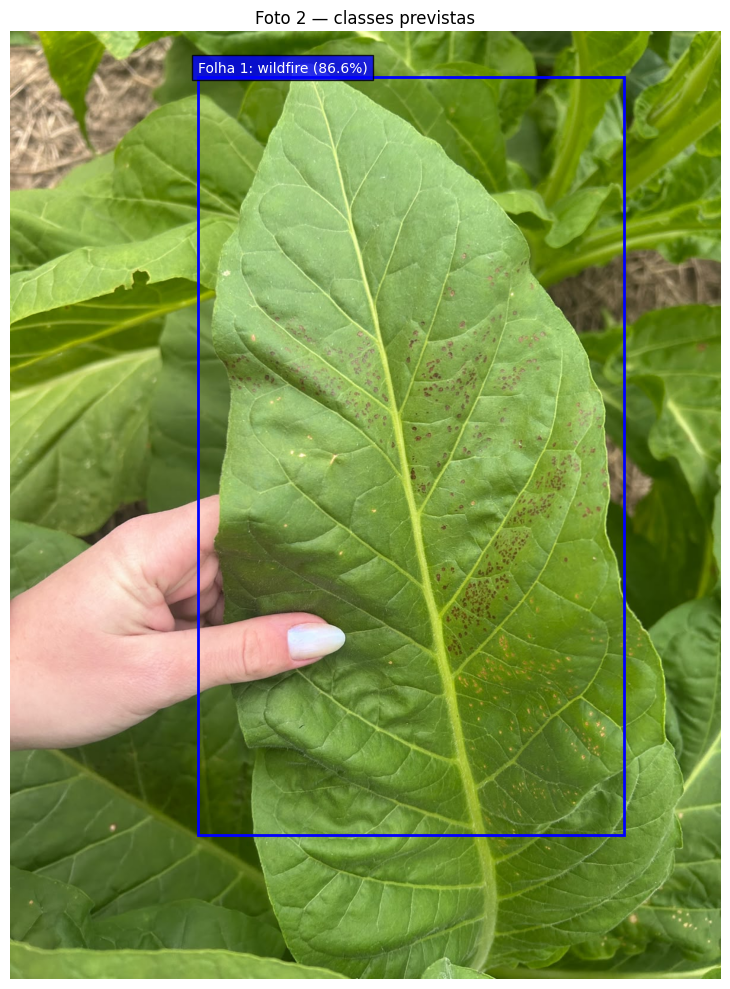


Foto 3 — folha 1
Confiança da detecção: 32.3%
Classe prevista: pvy
Confiança da classificação: 85.4%
Três classes mais prováveis:
  pvy: 85.4%
  wildfire: 12.3%
  black_shank: 0.9%


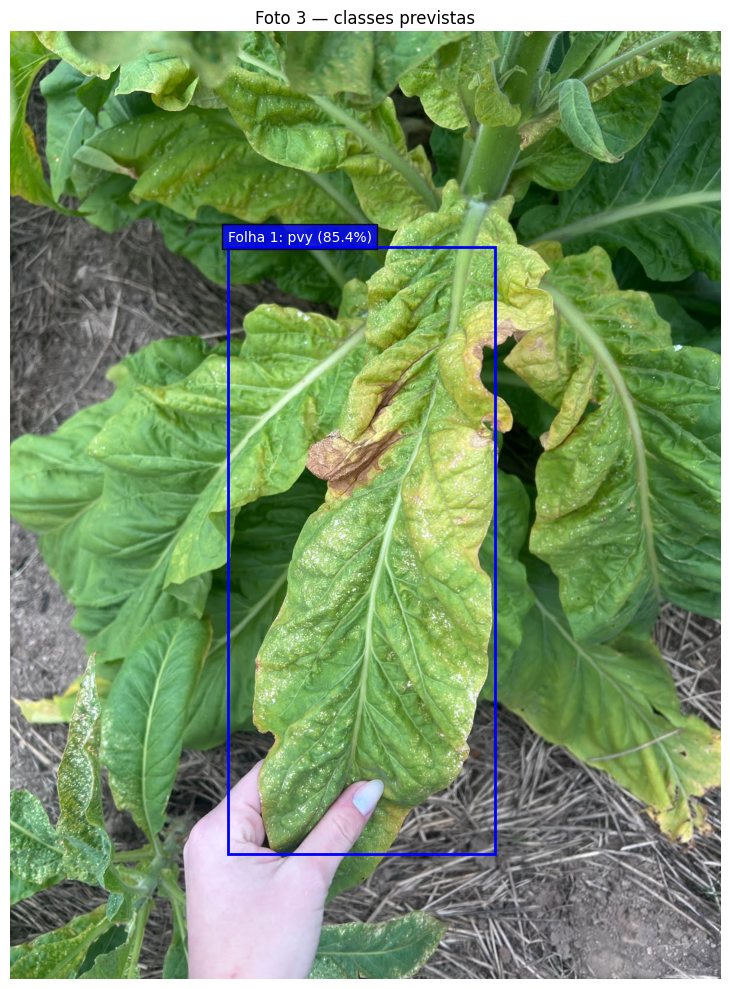


Processamento concluído!
Resultados salvos em: /content/SafraCerta_integracao_20261013_213020


In [8]:
import math
from datetime import datetime
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

OUTPUT_DIR = Path("/content") / (
    "SafraCerta_integracao_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)

CROP_DIR = OUTPUT_DIR / "recortes"
CROP_DIR.mkdir(parents=True, exist_ok=True)

CLASS_IMG_SIZE = (
    classificador.ckpt.get("train_args", {}).get("imgsz", 224)
)

resultados_integrados = []

for foto_index, caminho in enumerate(PHOTO_PATHS, start=1):
    deteccao = detector.predict(
        source=str(caminho),
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )[0]

    imagem = Image.fromarray(deteccao.orig_img[..., ::-1])
    largura, altura = imagem.size

    registro = {
        "arquivo": caminho.name,
        "folhas": []
    }

    fig, ax = plt.subplots(figsize=(8, 10))
    ax.imshow(imagem)
    ax.axis("off")
    ax.set_title(f"Foto {foto_index} — classes previstas")

    if len(deteccao.boxes) == 0:
        print(f"\n{caminho.name}: nenhuma folha detectada.")
        print("A classificação não será executada nesta foto.")

    for folha_index, caixa in enumerate(deteccao.boxes, start=1):
        coords = caixa.xyxy[0].cpu().tolist()

        x1 = max(0, min(largura, math.floor(coords[0])))
        y1 = max(0, min(altura, math.floor(coords[1])))
        x2 = max(0, min(largura, math.ceil(coords[2])))
        y2 = max(0, min(altura, math.ceil(coords[3])))

        if x2 <= x1 or y2 <= y1:
            continue

        recorte = imagem.crop((x1, y1, x2, y2))

        nome_recorte = (
            f"foto_{foto_index:02d}_folha_{folha_index:02d}.jpg"
        )
        recorte.save(CROP_DIR / nome_recorte)

        classificacao = classificador.predict(
            source=recorte,
            imgsz=CLASS_IMG_SIZE,
            device=DEVICE,
            verbose=False
        )[0]

        probabilidades = classificacao.probs
        classe_id = int(probabilidades.top1)
        classe = classificacao.names[classe_id]

        confianca_classe = float(probabilidades.top1conf.item())
        confianca_detector = float(caixa.conf.item())

        top3_ids = probabilidades.top5[:3]
        top3 = [
            {
                "classe": classificacao.names[int(i)],
                "confianca": float(probabilidades.data[int(i)].item())
            }
            for i in top3_ids
        ]

        registro["folhas"].append({
            "numero": folha_index,
            "caixa_xyxy": [x1, y1, x2, y2],
            "confianca_detector": confianca_detector,
            "classe_prevista": classe,
            "confianca_classificador": confianca_classe,
            "top3": top3,
            "recorte": f"recortes/{nome_recorte}"
        })

        print(f"\nFoto {foto_index} — folha {folha_index}")
        print(f"Confiança da detecção: {confianca_detector:.1%}")
        print(f"Classe prevista: {classe}")
        print(f"Confiança da classificação: {confianca_classe:.1%}")
        print("Três classes mais prováveis:")

        for alternativa in top3:
            print(
                f"  {alternativa['classe']}: "
                f"{alternativa['confianca']:.1%}"
            )

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="blue",
                linewidth=2
            )
        )

        ax.text(
            x1,
            max(0, y1 - 10),
            f"Folha {folha_index}: {classe} "
            f"({confianca_classe:.1%})",
            color="white",
            fontsize=10,
            bbox={"facecolor": "blue", "alpha": 0.8}
        )

    resultados_integrados.append(registro)

    plt.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"foto_{foto_index:02d}_resultado.png",
        bbox_inches="tight",
        dpi=150
    )
    plt.show()
    plt.close(fig)

print("\nProcessamento concluído!")
print("Resultados salvos em:", OUTPUT_DIR)

In [9]:
import json
import shutil
import hashlib
import ultralytics

ORIGINAL_DIR = OUTPUT_DIR / "fotos_originais"
ORIGINAL_DIR.mkdir(exist_ok=True)

for caminho in PHOTO_PATHS:
    shutil.copyfile(caminho, ORIGINAL_DIR / caminho.name)

resumo = {
    "fluxo": "detecção → recorte → classificação",
    "novo_treinamento": False,
    "modelos": {
        "detector_sha256": hashlib.sha256(
            DETECTOR_PATH.read_bytes()
        ).hexdigest(),
        "classificador_sha256": hashlib.sha256(
            CLASSIFIER_PATH.read_bytes()
        ).hexdigest()
    },
    "configuracao": {
        "ultralytics": ultralytics.__version__,
        "imgsz_detector": 640,
        "imgsz_classificador": CLASS_IMG_SIZE,
        "confianca_minima_detector": 0.25,
        "recorte": "caixa prevista, sem margem adicional"
    },
    "limitacoes": [
        "Teste exploratório com apenas três fotos.",
        "Classes reais das fotos não foram confirmadas.",
        "Não foram calculadas métricas do fluxo integrado.",
        "Algumas caixas deixam partes da folha fora do recorte.",
        "A foto 1 apresentou previsão incerta entre healthy e wildfire.",
        "Confiança do modelo não representa acurácia ou diagnóstico confirmado.",
        "Não foram testadas fotos sem folhas."
    ],
    "resultados": resultados_integrados
}

(OUTPUT_DIR / "resumo_integracao.json").write_text(
    json.dumps(resumo, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

(OUTPUT_DIR / "LEIA-ME.txt").write_text(
    "SafraCerta — teste de detecção e classificação integradas\n\n"
    "Dois modelos existentes executados em sequência, sem novo treinamento.\n"
    "O detector localiza a folha; o classificador analisa o recorte.\n"
    "Os pesos permanecem em dois arquivos separados.\n\n"
    "Conteúdo: fotos originais, recortes, imagens com classes previstas "
    "e resumo_integracao.json.\n\n"
    "As previsões não foram comparadas com classes reais confirmadas. "
    "Este teste não demonstra a acurácia do fluxo integrado.\n",
    encoding="utf-8"
)

zip_path = shutil.make_archive(
    str(OUTPUT_DIR),
    "zip",
    root_dir=str(OUTPUT_DIR)
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>